# Smart Crop Recommendation System — model workflow

This notebook audits the Kaggle Crop Recommendation Dataset, trains and compares three classifiers, calibrates the selected classifier using training-only cross-validation, and evaluates it on an untouched test split. It writes the model and metadata needed by the Streamlit app.

**Source and license:** [Crop Recommendation Dataset by Atharva Ingle](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset), Apache 2.0 as declared by its Kaggle metadata. The publisher says the data were assembled from Indian rainfall, climate, and fertilizer datasets, but does not document source-level lineage or the rainfall accumulation period. N/P/K are described as ratios without units. Review the dataset source and license before reuse.

**Feature-time mismatch:** live weather is current-condition data, while the dataset's weather feature time scales are unspecified. The model therefore uses only N, P, K, and pH. App weather is displayed as context and never enters the prediction. This educational dataset does not prove field-level crop suitability.

## 1. Imports and data location

Download `Crop_recommendation.csv` from the Kaggle page and place it in `data/raw/`. Install project requirements first with `python -m pip install -r requirements.txt`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "crop_app").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from crop_app.modeling import (
    FEATURES,
    TARGET,
    calibrate_selected_model,
    calibration_diagnostics,
    compare_candidates,
    load_dataset,
    make_metadata,
    save_artifacts,
    split_dataset,
)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Crop_recommendation.csv"
raw_data = pd.read_csv(DATA_PATH)
print(f"Source file: {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Raw shape: {raw_data.shape}")

Source file: data\raw\Crop_recommendation.csv
Raw shape: (2200, 8)


## 2. Inspect fields, ranges, missingness, duplicates, and suspicious values

No measurements or model results are assumed here. The cells below report values from the downloaded file. Repeated model rows (same N/P/K/pH and label) are removed before splitting, and identical soil-feature vectors are kept together across partitions. Missing feature values are imputed inside the model pipeline; missing crop labels are excluded.

In [2]:
display(raw_data.head())
display(raw_data.dtypes.rename("dtype").to_frame())
print("Columns:", raw_data.columns.tolist())
print("Exact duplicate source rows:", int(raw_data.duplicated().sum()))
if set([*FEATURES, TARGET]).issubset(raw_data.columns):
    print("Duplicate soil-feature/label rows:", int(raw_data.duplicated(subset=[*FEATURES, TARGET]).sum()))
display(raw_data.isna().sum().rename("missing").to_frame())

required = [*FEATURES, TARGET]
missing_columns = sorted(set(required) - set(raw_data.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

numeric = raw_data[FEATURES].apply(pd.to_numeric, errors="coerce")
print("Values that fail numeric conversion:")
display((raw_data[FEATURES].notna() & numeric.isna()).sum().rename("invalid numeric").to_frame())
display(numeric.describe().T)
print("pH outside 0–14:", int((numeric["ph"].notna() & ~numeric["ph"].between(0, 14)).sum()))
print("Rows with negative N/P/K:", int(numeric[["N", "P", "K"]].lt(0).any(axis=1).sum()))
print("Infinite feature values:", int(np.isinf(numeric.to_numpy(dtype=float)).sum()))

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


,dtype
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,str


Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
Exact duplicate source rows: 0
Duplicate soil-feature/label rows: 0


,missing
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


Values that fail numeric conversion:


,invalid numeric
N,0
P,0
K,0
ph,0


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091


pH outside 0–14: 0
Rows with negative N/P/K: 0
Infinite feature values: 0


,rows per crop label
label,
apple,100
banana,100
blackgram,100
chickpea,100
coconut,100
coffee,100
cotton,100
grapes,100
jute,100


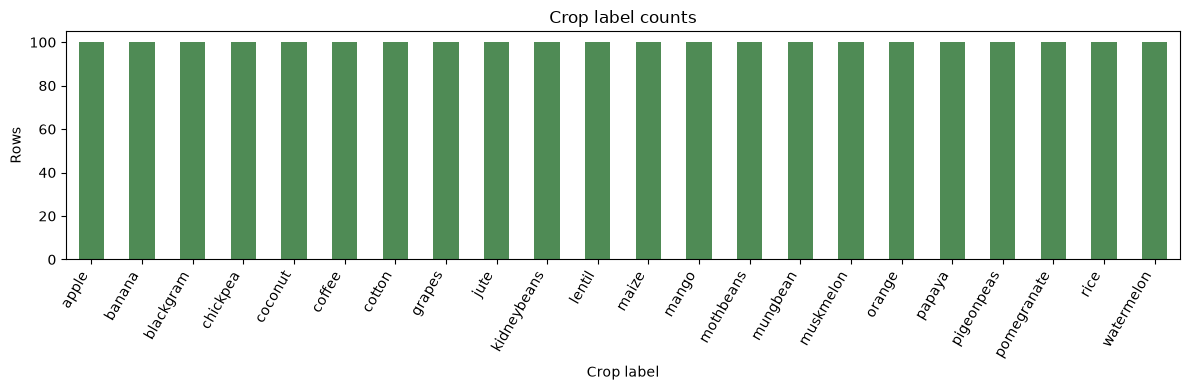

In [3]:
class_counts = raw_data[TARGET].value_counts(dropna=False).sort_index()
display(class_counts.rename("rows per crop label").to_frame())
ax = class_counts.plot(kind="bar", figsize=(12, 4), color="#4f8b55")
ax.set(title="Crop label counts", xlabel="Crop label", ylabel="Rows")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## 3. Explore useful relationships

These descriptive plots show the soil-feature distributions and pairwise relationships in the source file. They are exploratory, not evidence of causal effects.

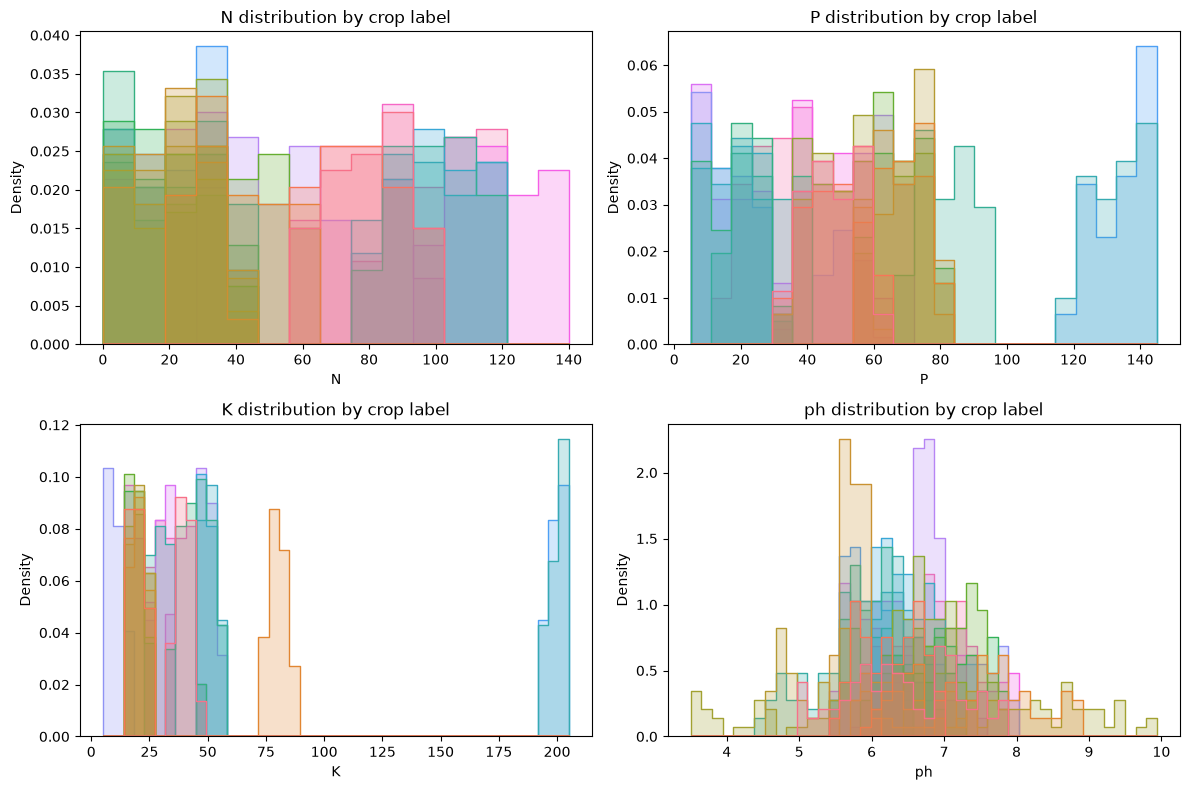

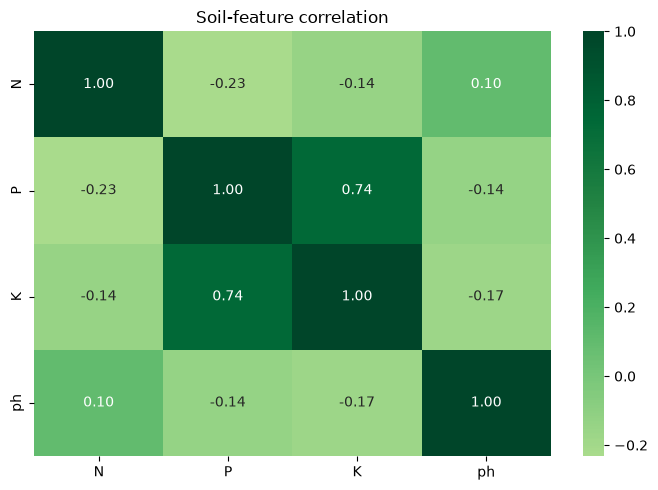

In [4]:
plot_data = numeric.replace([np.inf, -np.inf], np.nan).copy()
plot_data[TARGET] = raw_data[TARGET].astype("string")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, axis in zip(FEATURES, axes.flat):
    sns.histplot(data=plot_data, x=feature, hue=TARGET, element="step", stat="density", common_norm=False, ax=axis, legend=False)
    axis.set_title(f"{feature} distribution by crop label")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(numeric.corr(), annot=True, cmap="YlGn", center=0, fmt=".2f")
plt.title("Soil-feature correlation")
plt.tight_layout()
plt.show()

## 4. Prepare features and split without leakage

The selected model input is N, P, K, and pH only. Stratified, group-aware splits keep identical soil-feature vectors together: 20% for final testing, then 25% of the remaining development data for validation (about 60% train / 20% validation / 20% test). The validation set is used to select the classifier by macro-F1; the test set is not used for model selection.

In [5]:
clean_data = load_dataset(DATA_PATH)
print(f"Rows after removing missing labels and exact duplicates: {len(clean_data)}")
print("Remaining missing soil values (imputed within training folds):")
display(clean_data[FEATURES].isna().sum().rename("missing").to_frame())
display(clean_data[TARGET].value_counts().sort_index().rename("rows per label").to_frame())

X_train, X_validation, X_test, y_train, y_validation, y_test = split_dataset(clean_data)
print(f"Train: {len(X_train)} | validation: {len(X_validation)} | test: {len(X_test)}")
print("Training class counts:")
display(y_train.value_counts().sort_index().rename("train rows").to_frame())

Rows after removing missing labels and exact duplicates: 2200
Remaining missing soil values (imputed within training folds):


,missing
N,0
P,0
K,0
ph,0


,rows per label
label,
apple,100
banana,100
blackgram,100
chickpea,100
coconut,100
coffee,100
cotton,100
grapes,100
jute,100


Train: 1320 | validation: 440 | test: 440
Training class counts:


,train rows
label,
apple,60
banana,60
blackgram,60
chickpea,60
coconut,60
coffee,60
cotton,60
grapes,60
jute,60


## 5. Compare classifiers and select using validation macro-F1

All candidates use an imputer fitted only on training rows; Logistic Regression additionally scales features. Model selection is based on validation macro-F1 (accuracy is a tie-breaker), never on test results.

In [6]:
validation_results, candidates = compare_candidates(
    X_train, y_train, X_validation, y_validation
)
display(validation_results)
selected_name = str(validation_results.iloc[0]["model"])
print("Selected from validation results:", selected_name)

,model,validation_accuracy,validation_macro_f1
0,Random Forest,0.779545,0.776200
1,Decision Tree,0.740909,0.738102
2,Logistic Regression,0.668182,0.663195


Selected from validation results: Random Forest


## 6. Calibrate the selected model on training data only

Sigmoid calibration uses stratified, group-aware cross-validation confined to the training partition. The validation set remains used only for candidate selection, and the held-out test set remains untouched until final evaluation. Calibrated class probabilities describe model confidence within this dataset's labels, not a real-world chance of crop success.

In [7]:
selected_model = calibrate_selected_model(
    candidates[selected_name], X_train, y_train
)
print("Calibration method: sigmoid; calibration folds use training rows only.")

Calibration method: sigmoid; calibration folds use training rows only.


## 7. Final held-out test evaluation

Run this evaluation once after selection. Accuracy and macro-F1 summarize classification performance on the reserved test split. They do not establish reliability for farms, regions, seasons, or data outside this dataset.

Test accuracy: 0.8023
Test macro-F1: 0.8023
Classification report:
              precision    recall  f1-score   support

       apple       0.55      0.55      0.55        20
      banana       1.00      1.00      1.00        20
   blackgram       0.79      0.75      0.77        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.88      0.70      0.78        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       0.55      0.55      0.55        20
        jute       0.64      0.70      0.67        20
 kidneybeans       0.93      0.70      0.80        20
      lentil       0.58      0.55      0.56        20
       maize       1.00      1.00      1.00        20
       mango       0.75      0.90      0.82        20
   mothbeans       0.78      0.90      0.84        20
    mungbean       0.90      0.95      0.93        20
   muskmelon       0.61      0.70      0.65        20
      orange  

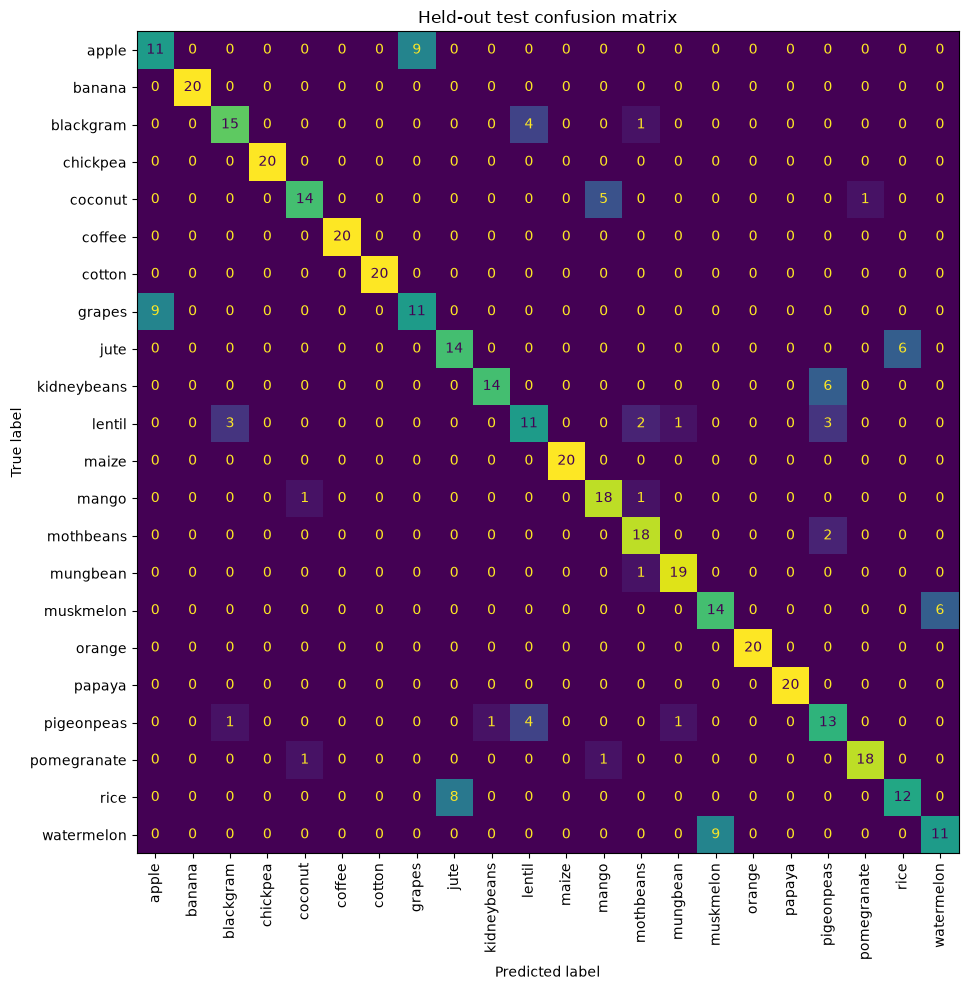

In [8]:
test_predictions = selected_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, test_predictions):.4f}")
print(f"Test macro-F1: {f1_score(y_test, test_predictions, average='macro', zero_division=0):.4f}")
print("Classification report:")
print(classification_report(y_test, test_predictions, zero_division=0))

class_order = list(selected_model.classes_)
matrix = confusion_matrix(y_test, test_predictions, labels=class_order)
fig, axis = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(matrix, display_labels=class_order).plot(
    ax=axis, xticks_rotation=90, colorbar=False
)
axis.set_title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

### Probability calibration diagnostics

Log loss, multiclass Brier score, and top-label expected calibration error are supplementary diagnostics on the same held-out test set. Finite test data do not guarantee calibration in new locations or populations.

Test log loss: 0.5895
Test multiclass Brier score: 0.2702
Test top-label ECE (10 fixed-width bins): 0.1140


,mean confidence,observed accuracy,count
0,0.234648,0.000000,1
1,0.367767,0.625000,8
2,0.458858,0.500000,48
3,0.549239,0.517857,56
4,0.647049,0.547619,42
5,0.753603,0.789474,57
6,0.829291,0.995614,228


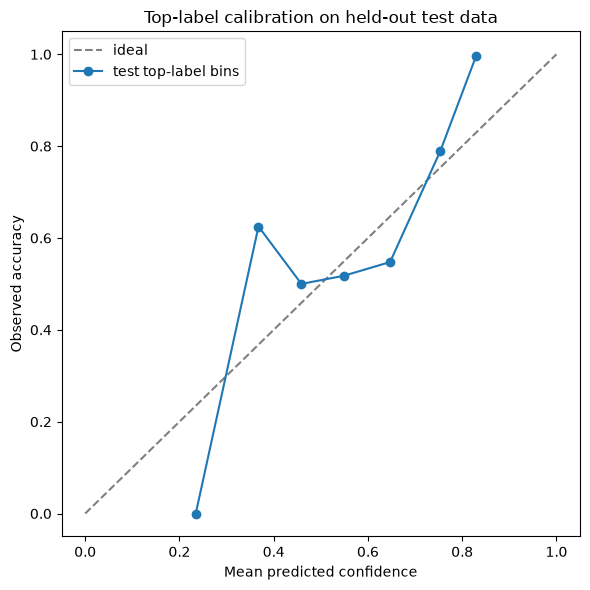

In [9]:
calibration_metrics, calibration_table = calibration_diagnostics(
    selected_model, X_test, y_test, bins=10
)
print(f"Test log loss: {calibration_metrics['log_loss']:.4f}")
print(f"Test multiclass Brier score: {calibration_metrics['multiclass_brier']:.4f}")
print(f"Test top-label ECE (10 fixed-width bins): {calibration_metrics['top_label_ece']:.4f}")
display(calibration_table)
plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="ideal")
if not calibration_table.empty:
    plt.plot(
        calibration_table["mean confidence"],
        calibration_table["observed accuracy"],
        marker="o",
        label="test top-label bins",
    )
plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.title("Top-label calibration on held-out test data")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Explain predictions and global feature influence

Permutation importance is calculated after model selection on the held-out test data, solely as a descriptive explanation. Local ablation replaces one feature at a time with its training median. Both methods describe model sensitivity/association, not causality; correlated features can make individual effects misleading.

,feature,mean macro-F1 decrease,standard deviation
2,K,0.465524,0.016060
1,P,0.437692,0.016665
0,N,0.378847,0.026666
3,ph,0.156432,0.013805


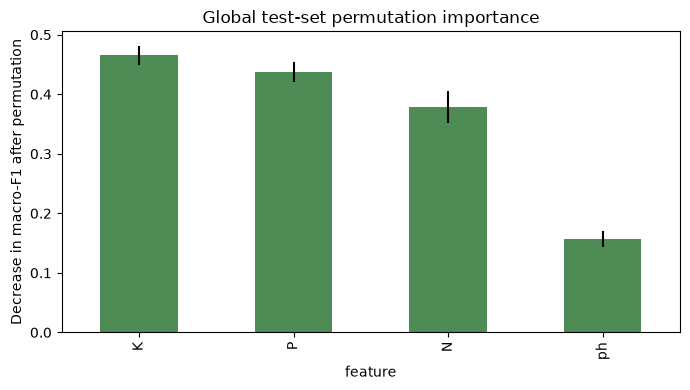

Example row: {'N': 85.0, 'P': 58.0, 'K': 41.0, 'ph': 7.038096361}
Top dataset label: jute; its internal calibrated model probability is 57.4% (numeric scores are omitted from the app due to the test-set calibration error above).


,feature,actual minus median baseline probability,submitted value,training median
0,N,0.545728,85.000000,37.000000
2,K,0.525712,41.000000,32.000000
1,P,-0.122152,58.000000,51.000000
3,ph,0.065875,7.038096,6.431795


In [10]:
permutation = permutation_importance(
    selected_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=1,
)
global_importance = pd.DataFrame(
    {
        "feature": FEATURES,
        "mean macro-F1 decrease": permutation.importances_mean,
        "standard deviation": permutation.importances_std,
    }
).sort_values("mean macro-F1 decrease", ascending=False)
display(global_importance)
global_importance.plot.bar(
    x="feature", y="mean macro-F1 decrease", yerr="standard deviation",
    legend=False, color="#4f8b55", figsize=(7, 4)
)
plt.ylabel("Decrease in macro-F1 after permutation")
plt.title("Global test-set permutation importance")
plt.tight_layout()
plt.show()

training_medians = X_train.median().to_dict()
example = X_test.iloc[0].to_dict()
example_frame = pd.DataFrame([example], columns=FEATURES)
example_probabilities = selected_model.predict_proba(example_frame)[0]
top_index = int(np.argmax(example_probabilities))
top_label = str(selected_model.classes_[top_index])
top_probability = float(example_probabilities[top_index])
print(f"Example row: {example}")
print(
    f"Top dataset label: {top_label}; its internal calibrated model probability is "
    f"{top_probability:.1%} (numeric scores are omitted from the app due to the "
    "test-set calibration error above)."
)
local_rows = []
for feature in FEATURES:
    ablated = example_frame.copy()
    ablated.loc[0, feature] = training_medians[feature]
    baseline = selected_model.predict_proba(ablated)[0][top_index]
    local_rows.append({
        "feature": feature,
        "actual minus median baseline probability": top_probability - baseline,
        "submitted value": example[feature],
        "training median": training_medians[feature],
    })
display(pd.DataFrame(local_rows).sort_values(
    "actual minus median baseline probability", key=lambda values: values.abs(), ascending=False
))

## 9. Save reproducible app artifacts

The serialized estimator includes its preprocessing and sigmoid calibration. Metadata records feature order, training ranges/medians, source, limitations, and score/explanation meanings. Generated files are ignored by Git; regenerate them from the downloaded source CSV when needed.

In [11]:
metadata = make_metadata(selected_name, X_train, calibration_metrics)
model_path, metadata_path = save_artifacts(
    selected_model, metadata, PROJECT_ROOT / "artifacts"
)
print(f"Saved model: {model_path.relative_to(PROJECT_ROOT)}")
print(f"Saved metadata: {metadata_path.relative_to(PROJECT_ROOT)}")

Saved model: artifacts\crop_model.joblib
Saved metadata: artifacts\model_metadata.json


## Interpretation and limitations

The notebook intentionally reports actual values calculated from the downloaded data rather than claiming any result in advance. The model is an educational classification exercise: source coverage, unspecified feature units/time scales, and possible differences from local farming conditions limit transferability. A held-out score or calibrated probability is not proof of real-world reliability.